# Imports and Data Loading

```json
{
    "pubmed_url": "https://pubmed.ncbi.nlm.nih.gov/38303729/",
    "data_url": "https://www.ebi.ac.uk/pride/archive/projects/PXD044834",
}
```

In [3]:
from pathlib import Path
import pandas
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, HTML

DATA_DIR = Path("../../raw")

huib_2026 = pandas.read_csv(
    DATA_DIR / "8604_txt/evidence.txt",
    sep="\t"
)

print("Data loaded.")

Data loaded.


/var/folders/_7/sysdjqtd0dj8tt9jvrzk6gh00000gn/T/ipykernel_46539/255940141.py:9: DtypeWarning: Columns (54: Reverse) have mixed types. Specify dtype option on import or set low_memory=False.
  huib_2026 = pandas.read_csv(


# Experiment Design

The authors used Orbitrap LC-MS to identify ISGylated proteins.

# Initial Observations

In [4]:
pandas.DataFrame({
    "non_null": huib_2026.notna().sum(),
    "null": huib_2026.isna().sum(),
    "null_%": (huib_2026.isna().sum() / len(huib_2026) * 100).round(1)
}).sort_values(by="null_%", ascending=False)

,non_null,null,null_%
Taxonomy IDs,0,333455,100.0
Potential contaminant,0,333455,100.0
Match q-value,0,333455,100.0
Reverse,1544,331911,99.5
Oxidation (M) Probabilities,11898,321557,96.4
...,...,...,...
Retention time,333455,0,0.0
Length,333455,0,0.0
Calibrated retention time,333455,0,0.0
Calibrated retention time start,333455,0,0.0


## MS-detected Peptides

MaxQuant software handles peptide identification through two different algorithms: Andromeda-based spectral search, and Match-Between-Runs that compares spectral data between runs.

*MS-detected*                   -   Peptides identified by standard fragmentation and spectral search.

*MBR-detected*                  -   Peptides not identified in earlier runs can be reassessed by matching spectra across runs.

*Secondary Peptide-detected*    -   An optional MaxQuant algorithm for isolating secondary peptide signals from with a primary peptide spectra.

*Ambiguous*                     -   Peptides matched to multiple gene groups.

In [5]:
total = huib_2026["Type"].notna().sum()
ms_detected = huib_2026["Type"].isin(["MULTI-MSMS", "MSMS", "MULTI"]).sum()
mbr_detected = huib_2026["Type"].isin(["MULTI-MATCH"]).sum()
secpep_detec = huib_2026["Type"].isin(["MULTI-SECPEP"]).sum()
ambiguous = huib_2026["Type"].isin(["MULTI-MATCH-MSMS"]).sum()

def get_proportion(val, total: int=total):
    return 100 * val / total

summary = pandas.DataFrame({
    "Peptides Identified": [total, get_proportion(total)], 
    "MS-detected": [ms_detected, get_proportion(ms_detected)],
    "MBR-detected": [mbr_detected, get_proportion(mbr_detected)],
    "Secondary Peptide-detected": [secpep_detec, get_proportion(secpep_detec)],
    "Ambiguous (>1 target)": [ambiguous, get_proportion(ambiguous)]
})

summary.index = ["count", "proportion"]
summary.T


,count,proportion
Peptides Identified,333455.0,100.000000
MS-detected,227613.0,68.258985
MBR-detected,81114.0,24.325321
Secondary Peptide-detected,5923.0,1.776252
Ambiguous (>1 target),18805.0,5.639442


Nearly three-quarters (74%) of all identified proteins were experimentally observed by fragmentation and spectral matching, indicating clean and consistent identification between runs.

At this point the focus will be assessing the quality of MBR and Secondary Peptides. A quick summary of the MS-detected targets shows the data is of high quality compared to target values:

* *Score* >= 40

* *Delta Score* >= 20

* *Length* >= 7

* *Mass Error* <= 5ppm, <= 0.0002 Da

* *PEP* < 0.01

In [6]:
huib_2026[
    [
        "Score", 
        "Delta score",
        "Length",
        "Mass error [Da]",
        "Mass error [ppm]",
        "PEP"
    ]
].describe()

,Score,Delta score,Length,Mass error [Da],Mass error [ppm],PEP
count,233536.000000,233536.000000,333455.000000,302761.000000,302761.000000,233536.000000
mean,111.083079,73.533329,15.190577,0.000025,0.031541,0.009246
std,42.113458,41.184784,5.678450,0.000491,0.673141,0.015680
min,1.703400,0.000000,7.000000,-0.007338,-9.040800,0.000000
25%,81.224000,43.985000,11.000000,-0.000160,-0.245590,0.000036
50%,103.110000,66.091000,14.000000,0.000018,0.027975,0.001180
75%,132.510000,95.121000,18.000000,0.000203,0.303010,0.010746
max,449.700000,431.370000,53.000000,0.007673,10.390000,0.069531


# MBR-identified peptides

The MBR algorithm will attempt to rematch peptides with an identified MS1 peak and no corresponding MS2 profile. If the MS1 peak can be matched to the MS2 profile generated from one of the other concurrent channels, improving the coverage of identified targets.

The easiest approach to checking the quality of these peptides is comparing the difference in **retention time** and **m/z** deviations. I am recreating analyses present in `eda/huibregtse_2024/report/multiqc_report.html` but this confirms the peptides identified with MBR are of good quality.

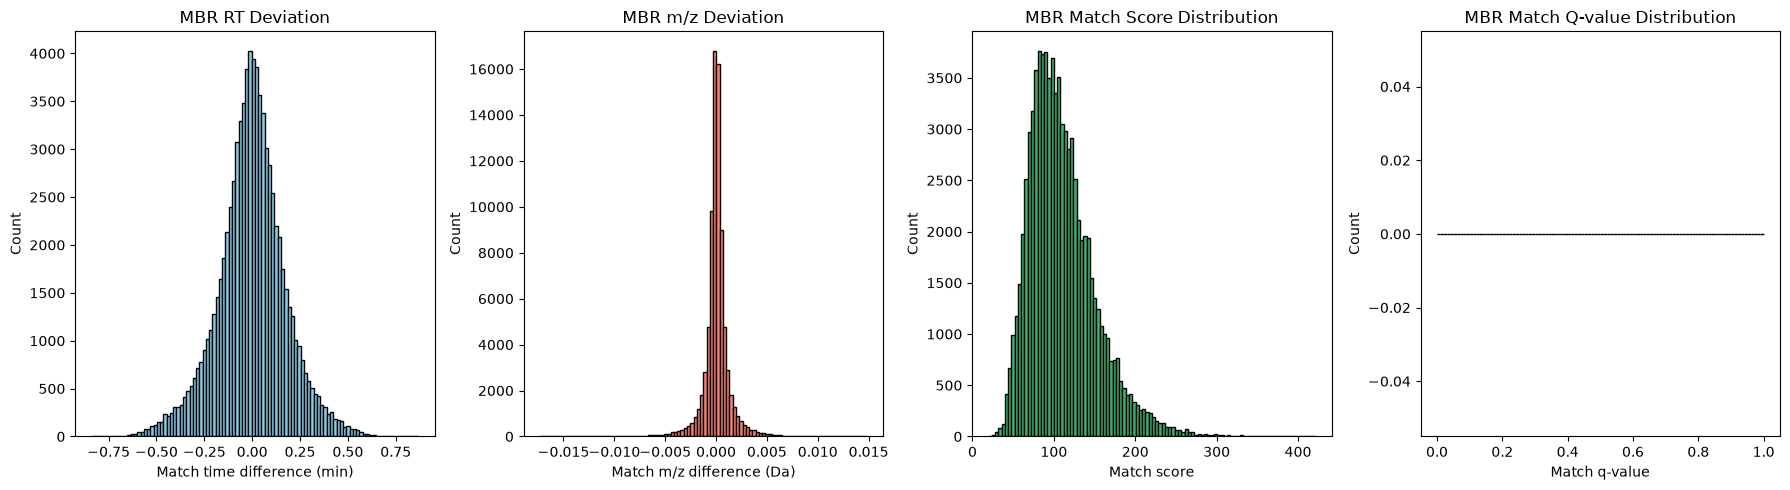

--- MBR Quality Summary ---
Total MBR entries: 81114
Median RT deviation:  -0.002 min
RT deviation Std Dev: 0.177 min
Median m/z deviation: 0.0000 Da
Median Match score:   103.31
Median Match q-value: nan
Frac. q-value < 0.01: 0.0%


In [7]:
mbr = huib_2026[huib_2026["Type"] == "MULTI-MATCH"].copy()

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].hist(mbr["Match time difference"].dropna(), bins=100, color="skyblue", edgecolor="black")
axes[0].set_title("MBR RT Deviation")
axes[0].set_xlabel("Match time difference (min)")
axes[0].set_ylabel("Count")

axes[1].hist(mbr["Match m/z difference"].dropna(), bins=100, color="salmon", edgecolor="black")
axes[1].set_title("MBR m/z Deviation")
axes[1].set_xlabel("Match m/z difference (Da)")
axes[1].set_ylabel("Count")

axes[2].hist(mbr["Match score"].dropna(), bins=100, color="mediumseagreen", edgecolor="black")
axes[2].set_title("MBR Match Score Distribution")
axes[2].set_xlabel("Match score")
axes[2].set_ylabel("Count")

axes[3].hist(mbr["Match q-value"].dropna(), bins=100, color="firebrick", edgecolor="black")
axes[3].set_title("MBR Match Q-value Distribution")
axes[3].set_xlabel("Match q-value")
axes[3].set_ylabel("Count")

plt.tight_layout()
plt.show()

print("--- MBR Quality Summary ---")
print(f"Total MBR entries: {len(mbr)}")
print(f"Median RT deviation:  {mbr['Match time difference'].median():.3f} min")
print(f"RT deviation Std Dev: {mbr['Match time difference'].std():.3f} min")
print(f"Median m/z deviation: {mbr['Match m/z difference'].median():.4f} Da")
print(f"Median Match score:   {mbr['Match score'].median():.2f}")
print(f"Median Match q-value: {mbr['Match q-value'].median():.4f}")
print(f"Frac. q-value < 0.01: {(mbr['Match q-value'] < 0.01).mean():.1%}")

## Cleaning and Filtering IDs

In [8]:

def _silkg_uniprot_id(elem):
    return f"silkg:Protein:9606:{elem}"


def build_node_ids(series):
    return [_silkg_uniprot_id(uid) for uid in series]


huib_targets = huib_2026[
        (huib_2026["Reverse"] != "+") 
    &   (huib_2026["Potential contaminant"] != "+") 
    &   (huib_2026["Type"].isin(["MULTI-MSMS", "MSMS"])) 
    &   (huib_2026["Leading proteins"].notna())
    &   (huib_2026["GlyGly (K)"] > 0)]

filtered_targets = huib_targets[
        (huib_targets["Score"] >= 40)
    &   (huib_targets["Delta score"] >= 20)
    &   (huib_targets["Length"] >= 7)
    &   (huib_targets["Mass error [ppm]"] < 5)
    &   (huib_targets["PEP"] < 0.01)].copy()

protein_ids = filtered_targets["Leading proteins"].dropna().str.split(";").explode().unique().tolist()

silkg_ids = build_node_ids(protein_ids)
silkg_ids[0:10]

pandas.DataFrame({
    "total peptides": [len(huib_2026)],
    "MS-detected peptides": [len(huib_targets)],
    "Filtered peptides": [len(filtered_targets)],
    "Unique proteins": [len(protein_ids)]
}).T


,0
total peptides,333455
MS-detected peptides,93071
Filtered peptides,65994
Unique proteins,4474
